In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/pokemon.csv
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/abomasnow.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/abra.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/absol.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/accelgor.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/aegislash-blade.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/aerodactyl.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/aggron.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/aipom.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/alakazam.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/alomomola.png
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images/altaria.png
/kaggle/input/datasets/vis

In [2]:
import os
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch

In [3]:
path = "/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types"

df = pd.read_csv(os.path.join(path, "pokemon.csv"))

print(df.head())
print(df.shape)

         Name  Type1   Type2   Evolution
0   bulbasaur  Grass  Poison     ivysaur
1     ivysaur  Grass  Poison    venusaur
2    venusaur  Grass  Poison         NaN
3  charmander   Fire     NaN  charmeleon
4  charmeleon   Fire     NaN   charizard
(809, 4)


In [4]:
df = df[["Type2", "Type1"]].dropna().copy()

X = df[["Type2"]].copy()
y = df["Type1"].copy()

In [5]:
le_X = LabelEncoder()
le_y = LabelEncoder()

X["Type2"] = le_X.fit_transform(X["Type2"])
y = le_y.fit_transform(y)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [7]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (324, 1)
Testing data: (81, 1)
Training labels: (324,)
Testing labels: (81,)


In [8]:
import os
import pandas as pd
import torch
import torchvision
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

path = "/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types"

print(os.listdir(path))

['images', 'pokemon.csv']


In [9]:
for root, dirs, files in os.walk(path):
    print(root)
    print("Number of images:", len(files))

/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types
Number of images: 1
/kaggle/input/datasets/vishalsubbiah/pokemon-images-and-types/images
Number of images: 809


In [10]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [11]:
image_path = os.path.join(path, "images")

print("Total images:", len(os.listdir(image_path)))

Total images: 809


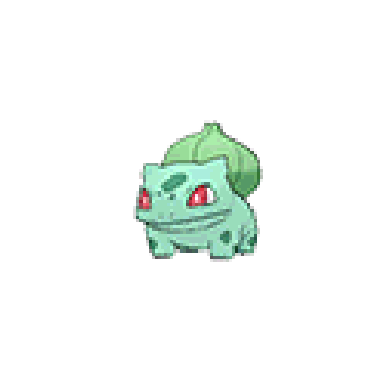

In [12]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(os.path.join(image_path, "bulbasaur.png"))

plt.imshow(img)
plt.axis("off")
plt.show()

In [13]:
df = pd.read_csv(os.path.join(path, "pokemon.csv"))

df["image"] = df["Name"].str.lower() + ".png"

print(df[["Name", "Type1", "image"]].head())

         Name  Type1           image
0   bulbasaur  Grass   bulbasaur.png
1     ivysaur  Grass     ivysaur.png
2    venusaur  Grass    venusaur.png
3  charmander   Fire  charmander.png
4  charmeleon   Fire  charmeleon.png


In [14]:
df = df[
    df["image"].isin(os.listdir(image_path))
].copy()

print("Available images:", len(df))

Available images: 809


In [15]:
X = df["image"]
y = df["Type1"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 647
Testing images: 162


In [16]:
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

In [17]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [18]:
class PokemonDataset(Dataset):

    def __init__(self, X, y, image_path, transform=None):
        self.X = X.reset_index(drop=True)
        self.y = y.reset_index(drop=True)
        self.image_path = image_path
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        img_name = self.X.iloc[index]
        img_path = os.path.join(self.image_path, img_name)

        image = Image.open(img_path).convert("RGB")

        label = self.y.iloc[index]

        if self.transform:
            image = self.transform(image)

        return image, label

In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train = pd.Series(le.fit_transform(y_train))
y_test = pd.Series(le.transform(y_test))

print("Classes:", le.classes_)
print("Number of classes:", len(le.classes_))

Classes: ['Bug' 'Dark' 'Dragon' 'Electric' 'Fairy' 'Fighting' 'Fire' 'Flying'
 'Ghost' 'Grass' 'Ground' 'Ice' 'Normal' 'Poison' 'Psychic' 'Rock' 'Steel'
 'Water']
Number of classes: 18


In [20]:
train_dataset = PokemonDataset(
    X_train, y_train, image_path, transform
)

test_dataset = PokemonDataset(
    X_test, y_test, image_path, transform
)

In [21]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [22]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

In [24]:
class MyNN(nn.Module):

    def __init__(self, input_features, num_classes):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(input_features, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

In [25]:
num_classes = len(le.classes_)

model = MyNN(
    input_features=3,
    num_classes=num_classes
)

print(model)

MyNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=64, out_features=18, bias=True)
  )
)


In [26]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Using device:", device)

Using device: cpu


In [27]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [28]:
epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {total_loss/len(train_loader):.4f}, "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch [1/10], Loss: 3.0800, Accuracy: 10.20%
Epoch [2/10], Loss: 2.8556, Accuracy: 14.06%
Epoch [3/10], Loss: 2.7305, Accuracy: 14.37%
Epoch [4/10], Loss: 2.6641, Accuracy: 18.55%
Epoch [5/10], Loss: 2.5808, Accuracy: 20.56%
Epoch [6/10], Loss: 2.5535, Accuracy: 20.40%
Epoch [7/10], Loss: 2.4249, Accuracy: 24.88%
Epoch [8/10], Loss: 2.3388, Accuracy: 27.36%
Epoch [9/10], Loss: 2.2960, Accuracy: 29.06%
Epoch [10/10], Loss: 2.2233, Accuracy: 30.60%


In [29]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 25.31%


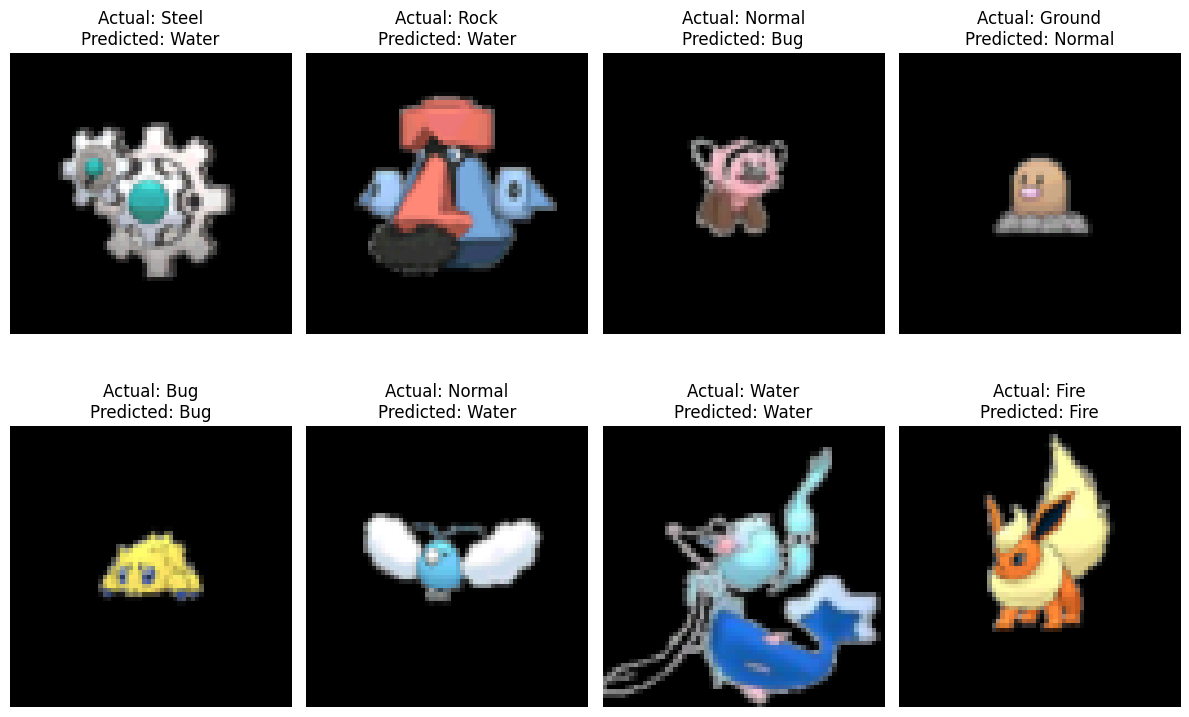

In [30]:
import matplotlib.pyplot as plt

model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)
    predictions = torch.argmax(outputs, dim=1)

images = images.cpu()

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i+1)

    plt.imshow(images[i].permute(1, 2, 0))

    actual = le.classes_[labels[i].item()]
    predicted = le.classes_[predictions[i].item()]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
torch.save(model.state_dict(), "pokemon_cnn.pth")

print("Model saved successfully!")

Model saved successfully!
